# Chapitre 6 - Exercices 6.7 à 6.12

Validation croisée des polynômes locaux, densité jointe et Nadaraya-Watson, Bayes naïf
contre modèle additif logistique, critère $C_p$, dégénérescence de la vraisemblance des
mélanges gaussiens, analyse discriminante linéaire locale sur les chiffres manuscrits.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch06_noyaux as nk
set_style()
GREEN, YELLOW, RED = COLORS[2], COLORS[3], COLORS[7]
rng = np.random.RandomState(0)

## Exercice 6.7 : Validation croisée leave-one-out des polynômes locaux

**Énoncé.** Établir une expression de la somme des carrés des résidus de validation
croisée « leave-one-out » pour la régression polynomiale locale.

**Notations.** $\hat f(x_0) = \sum_j l_j(x_0)y_j$ est l'ajustement polynomial local (degré
$k$, largeur **métrique** $\lambda$) sur toutes les données, et $\hat f^{(-i)}(x_i)$
l'ajustement en $x_i$ obtenu **sans** l'observation $i$. On note
$S_{ii} = l_i(x_i)$ le $i$-ème terme diagonal de la matrice de lissage. On cherche
$$
\mathrm{CV} = \sum_{i=1}^N\big(y_i - \hat f^{(-i)}(x_i)\big)^2 .
$$

**Étape 1 : retirer $i$ = mettre son poids à zéro.** En la cible $x_i$, l'ajustement est
un problème de moindres carrés pondérés de poids $w_j = K_\lambda(x_i, x_j)$. Avec une
largeur métrique, retirer l'observation $i$ ne modifie pas les poids des autres
observations : $\hat f^{(-i)}(x_i)$ est la valeur en $x_i$ du polynôme $\hat P^{(-i)}$ qui
minimise $\sum_{j\ne i}w_j(y_j - P(x_j))^2$.

**Étape 2 : l'astuce de la réponse modifiée.** Remplaçons $y_i$ par
$y_i^* = \hat P^{(-i)}(x_i) = \hat f^{(-i)}(x_i)$ et gardons les autres $y_j$. Pour tout
polynôme $P$ :
$$
\sum_{j\ne i}w_j(y_j - P(x_j))^2 + w_i(y_i^* - P(x_i))^2 \ \ge\ \sum_{j\ne i}w_j(y_j - \hat P^{(-i)}(x_j))^2 + 0,
$$
et l'égalité a lieu pour $P = \hat P^{(-i)}$. Donc $\hat P^{(-i)}$ est aussi l'ajustement
**avec toutes les données** et la réponse $y^*$. Par linéarité :
$$
\hat f^{(-i)}(x_i) = \sum_{j\ne i}l_j(x_i)\,y_j + l_i(x_i)\,\hat f^{(-i)}(x_i)
= \hat f(x_i) - S_{ii}y_i + S_{ii}\hat f^{(-i)}(x_i).
$$

**Étape 3 : on résout.** Si $S_{ii}\ne 1$ :
$\hat f^{(-i)}(x_i) = \dfrac{\hat f(x_i) - S_{ii}y_i}{1 - S_{ii}}$, et donc
$$
y_i - \hat f^{(-i)}(x_i) = \frac{y_i - S_{ii}y_i - \hat f(x_i) + S_{ii}y_i}{1 - S_{ii}}
= \frac{y_i - \hat f(x_i)}{1 - S_{ii}},
\qquad
\boxed{\ \mathrm{CV} = \sum_{i=1}^N\left(\frac{y_i - \hat f(x_i)}{1 - S_{ii}}\right)^2\ }
$$
Un seul ajustement suffit : il faut les résidus ordinaires et la diagonale de $\mathbf S_\lambda$.

> **Remarque.** Avec une largeur des **k plus proches voisins**, retirer $x_i$ change la
> fenêtre en $x_i$ (il faut aller chercher un voisin de plus) : les poids des autres
> observations changent et la formule n'est plus qu'une **approximation**.

Vérification numérique : formule contre $N$ réajustements, pour une largeur métrique
(égalité exacte) et une largeur de k-ppv (approximation).

In [2]:
N = 100
x = np.sort(rng.uniform(0, 1, N))
y = np.sin(4 * x) + np.sqrt(1 / 3) * rng.normal(size=N)

def brute_cv(lam=None, k=None, degree=1):
    res = []
    for i in range(N):
        m = np.arange(N) != i
        kk = None if k is None else k
        res.append(y[i] - nk.local_regression(x[i:i + 1], x[m], y[m], lam=lam, k=kk,
                                              degree=degree, kernel="tricube")[0])
    return np.sum(np.array(res) ** 2)

for deg in (0, 1, 2):
    S = nk.smoother_matrix(x, lam=0.3, degree=deg, kernel="tricube")
    print("métrique, degré %d : formule = %.6f   réajustements = %.6f"
          % (deg, N * nk.loocv_error(S, y), brute_cv(lam=0.3, degree=deg)))
S = nk.smoother_matrix(x, k=30, degree=1, kernel="tricube")
print("30-ppv,   degré 1 : formule = %.6f   réajustements = %.6f"
      % (N * nk.loocv_error(S, y), brute_cv(k=30, degree=1)))

métrique, degré 0 : formule = 36.589829   réajustements = 36.589829
métrique, degré 1 : formule = 34.878172   réajustements = 34.878172
métrique, degré 2 : formule = 35.485491   réajustements = 35.485491
30-ppv,   degré 1 : formule = 35.777138   réajustements = 35.677039


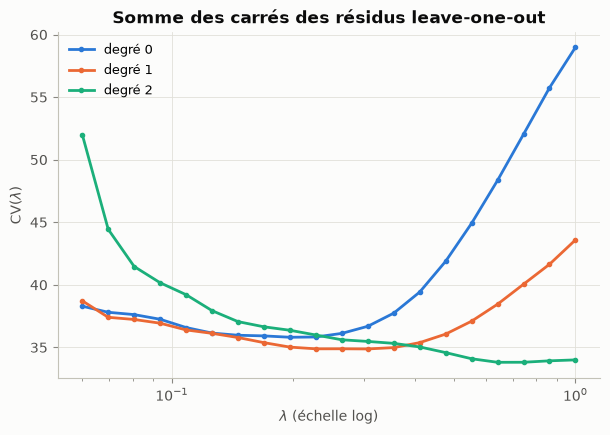

In [3]:
lams = np.geomspace(0.06, 1.0, 20)
fig = plt.figure(figsize=(7, 4.5))
for deg, c in zip((0, 1, 2), (BLUE, ORANGE, GREEN)):
    cvs = [N * nk.loocv_error(nk.smoother_matrix(x, lam=l, degree=deg, kernel="tricube"), y) for l in lams]
    plt.semilogx(lams, cvs, "o-", ms=3, color=c, label="degré %d" % deg)
plt.title("Somme des carrés des résidus leave-one-out")
plt.xlabel("$\\lambda$ (échelle log)"); plt.ylabel("CV($\\lambda$)"); plt.legend(); plt.show()

> **À retenir.** Pour tout lisseur obtenu par moindres carrés pondérés à poids fixes
> (polynômes locaux à largeur métrique), le résidu leave-one-out est le résidu ordinaire
> divisé par $1 - S_{ii}$ : la validation croisée ne coûte pas plus qu'un ajustement.

## Exercice 6.8 : Densité jointe par noyaux et Nadaraya-Watson

**Énoncé.** Pour une réponse continue $Y$ et un prédicteur $X$, on estime la densité jointe
de $(X, Y)$ par un estimateur à noyau gaussien bivarié, de noyau produit
$\varphi_\lambda(X)\varphi_\lambda(Y)$. Montrer que l'espérance conditionnelle
$\mathbb E(Y\mid X)$ déduite de cette estimation est un estimateur de Nadaraya-Watson.
Étendre ce résultat à la classification, en proposant un noyau adapté à l'estimation de la
loi jointe d'un $X$ continu et d'un $Y$ discret.

**Solution (cas continu).** L'estimateur de la densité jointe est
$$
\hat f(x, y) = \frac1N\sum_{i=1}^N\varphi_\lambda(x - x_i)\,\varphi_\lambda(y - y_i).
$$
- **Marge en $x$** : on intègre en $y$ ; comme $\int\varphi_\lambda(y - y_i)\,dy = 1$,
  $\hat f_X(x) = \int\hat f(x,y)\,dy = \frac1N\sum_i\varphi_\lambda(x - x_i)$.
- **Moment** : $\int y\,\varphi_\lambda(y - y_i)\,dy = y_i$ (espérance d'une
  $\mathcal N(y_i, \lambda^2)$), donc $\int y\hat f(x,y)\,dy = \frac1N\sum_i\varphi_\lambda(x - x_i)\,y_i$.
- **Espérance conditionnelle** :
$$
\hat{\mathbb E}(Y\mid X = x) = \frac{\int y\,\hat f(x,y)\,dy}{\hat f_X(x)}
= \frac{\sum_i\varphi_\lambda(x - x_i)\,y_i}{\sum_i\varphi_\lambda(x - x_i)},
$$
l'estimateur de Nadaraya-Watson (6.2) à noyau gaussien. La largeur en $y$ n'intervient pas
(seule compte la propriété « moyenne $y_i$ » du noyau en $y$).

Vérification par intégration numérique sur une grille fine en $y$ :

In [4]:
lam = 0.08
ygrid = np.linspace(y.min() - 3, y.max() + 3, 4001)
dy = ygrid[1] - ygrid[0]
for x0 in [0.1, 0.5, 0.9]:
    fxy = np.mean(norm.pdf(x0, x, lam)[:, None] * norm.pdf(ygrid[None, :], y[:, None], 0.5), axis=0)
    cond = np.sum(ygrid * fxy) * dy / (np.sum(fxy) * dy)
    print("x0 = %.1f : E(Y|X) par intégration = %.6f   Nadaraya-Watson = %.6f"
          % (x0, cond, nk.nadaraya_watson([x0], x, y, lam=lam, kernel="gaussian")[0]))

x0 = 0.1 : E(Y|X) par intégration = 0.653526   Nadaraya-Watson = 0.653526
x0 = 0.5 : E(Y|X) par intégration = 0.902472   Nadaraya-Watson = 0.902472
x0 = 0.9 : E(Y|X) par intégration = -0.393622   Nadaraya-Watson = -0.393622


**Extension à la classification.** Pour $G\in\{1,\dots,J\}$ discret, on remplace le noyau
en $y$ par un noyau **discret** sur les classes. Le plus simple est l'indicatrice
$K(g, g_i) = \mathbf 1(g = g_i)$ (une « masse de Dirac », qui somme à 1 sur les classes) :
$$
\hat f(x, g) = \frac1N\sum_i\varphi_\lambda(x - x_i)\,\mathbf 1(g_i = g),
\qquad
\hat\Pr(G = j\mid X = x) = \frac{\hat f(x, j)}{\sum_g\hat f(x, g)}
= \frac{\sum_i\varphi_\lambda(x - x_i)\mathbf 1(g_i = j)}{\sum_i\varphi_\lambda(x - x_i)} .
$$
C'est Nadaraya-Watson sur les indicatrices, et aussi la règle (6.25) avec
$\hat\pi_j = N_j/N$ et $\hat f_j$ l'estimateur de Parzen de la classe $j$ (même $\lambda$).

On peut aussi lisser en $g$ avec le noyau d'Aitchison-Aitken
$K_h(g, g_i) = 1 - h$ si $g = g_i$, $h/(J-1)$ sinon ($0\le h\le (J-1)/J$), qui somme
encore à 1 sur les classes. On obtient alors
$\hat\Pr_h(G = j\mid x) = (1 - h)\hat p_j(x) + \frac{h}{J-1}(1 - \hat p_j(x))$, où
$\hat p_j$ est la probabilité précédente : un **rétrécissement** vers la loi uniforme.

In [5]:
x3 = rng.uniform(0, 1, 200)
g3 = (x3 + 0.3 * rng.normal(size=200) > 0.5).astype(int) + (x3 > 0.8)
q = np.array([0.2, 0.5, 0.9])
post, cl = nk.kde_posterior(q, x3, g3, 0.1)
nw = np.column_stack([nk.nadaraya_watson(q, x3, (g3 == j).astype(float), lam=0.1, kernel="gaussian")
                      for j in cl])
print("écart max entre (6.25) et Nadaraya-Watson sur les indicatrices : %.2e" % np.max(np.abs(post - nw)))

écart max entre (6.25) et Nadaraya-Watson sur les indicatrices : 2.22e-16


> **À retenir.** L'espérance conditionnelle d'une densité jointe estimée par noyau produit
> est l'estimateur de Nadaraya-Watson ; avec un noyau indicatrice sur la classe, on retrouve
> la classification par densités (6.25), et un noyau discret lissé rétrécit les
> probabilités vers l'uniforme.

## Exercice 6.9 : Bayes naïf et modèle additif logistique

**Énoncé.** Étudier les différences entre le modèle bayésien naïf (6.27) et un modèle
additif généralisé logistique, du point de vue (a) des hypothèses du modèle et (b) de
l'estimation. Si toutes les variables $X_k$ sont discrètes, que peut-on dire du GAM
correspondant ?

**Rappel.** Les deux modèles ont un logit **additif** :
$\log\frac{\Pr(G=1\mid X)}{\Pr(G=0\mid X)} = \alpha + \sum_k g_k(X_k)$. Pour le Bayes naïf,
(6.27) donne $\alpha = \log(\pi_1/\pi_0)$ et $g_k = \log(f_{1k}/f_{0k})$.

**(a) Hypothèses.**
- Bayes naïf : modèle **génératif** ; il spécifie toute la loi jointe de $(X, G)$, avec
  l'hypothèse forte d'**indépendance conditionnelle** des $X_k$ sachant la classe.
- GAM logistique : modèle **discriminant** ; il ne spécifie que la loi conditionnelle de
  $G$ sachant $X$, avec pour seule hypothèse l'additivité du logit. La loi de $X$ est libre.
- Toute loi « Bayes naïf » produit un logit additif, mais la réciproque est fausse : par
  exemple deux classes gaussiennes de même covariance **non diagonale** (cadre de l'ADL)
  ont un logit linéaire, donc additif, sans indépendance conditionnelle. Le GAM est donc
  un modèle **plus général**.

**(b) Estimation.**
- Bayes naïf : chaque $f_{jk}$ est estimée **séparément** (noyau 1D, histogramme), en
  maximisant la vraisemblance **jointe** ; c'est explicite, sans itération, et les $g_k$
  s'obtiennent comme log-rapports.
- GAM : on maximise la vraisemblance **conditionnelle** $\prod_i\Pr(g_i\mid x_i)$ pour
  toutes les fonctions $g_k$ **conjointement** (backfitting + scores locaux, chapitre 9). Les
  $g_k$ s'ajustent les unes aux autres : si deux variables sont corrélées, le GAM ne compte
  pas deux fois la même information, contrairement au Bayes naïf.
- C'est la même relation qu'entre l'ADL et la régression logistique (section 4.4.5) : si
  l'hypothèse naïve est vraie, le Bayes naïf est plus efficace (moins de variance) ; sinon,
  il est biaisé alors que le GAM reste consistant pour le meilleur logit additif.

**Variables toutes discrètes.** Si $X_k$ prend les modalités $v_{k1},\dots,v_{km_k}$, une
fonction $g_k$ est entièrement décrite par ses $m_k$ valeurs :
$g_k(X_k) = \sum_{r}\gamma_{kr}\mathbf 1(X_k = v_{kr})$. Le GAM logistique est alors
exactement une **régression logistique linéaire sur les indicatrices** des modalités
(modèle à effets principaux, sans interactions, avec une modalité de référence par
variable) ; il n'y a plus aucun lissage. Le Bayes naïf correspond au **même** modèle (même
famille de logits), mais avec $\hat\gamma_{kr} = \log\big(\hat p_{1k}(v_{kr})/\hat p_{0k}(v_{kr})\big)$
calculé à partir des tables de fréquences de chaque classe.

### Illustration : variables binaires redondantes

Trois variables binaires : $X_1$ et $X_3$ indépendantes sachant la classe, et $X_2$ une
**copie bruitée** de $X_1$ ($X_2 = X_1$ avec probabilité 0,9). L'hypothèse naïve est fausse
pour $(X_1, X_2)$. On compare le Bayes naïf (fréquences lissées) et le GAM discret
(logistique sur indicatrices) par la log-vraisemblance de test (perte logarithmique).

In [6]:
def simulate(n, rs):
    gg = rs.binomial(1, 0.5, n)
    x1 = rs.binomial(1, np.where(gg == 1, 0.7, 0.3))
    x2 = np.where(rs.uniform(size=n) < 0.9, x1, 1 - x1)
    x3 = rs.binomial(1, np.where(gg == 1, 0.6, 0.4))
    return np.column_stack([x1, x2, x3]).astype(float), gg

def logloss(p, gg):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return -np.mean(gg * np.log(p) + (1 - gg) * np.log(1 - p))

Xtest, gtest = simulate(20000, np.random.RandomState(1))
sizes = [30, 60, 120, 250, 500, 1000, 4000]
res = {"Bayes naïf": [], "GAM (logistique sur indicatrices)": []}
for n in sizes:
    l_nb, l_gam = [], []
    for r in range(40):
        Xa, ga = simulate(n, rng)
        nb = nk.NaiveBayesKDE(discrete=[True] * 3).fit(Xa, ga)
        l_nb.append(logloss(nb.predict_proba(Xtest)[:, 1], gtest))
        Z = np.column_stack([np.ones(n), Xa])          # indicatrices (modalité de référence 0)
        b = nk.logistic_irls(Z, ga, ridge=1e-2)
        l_gam.append(logloss(1 / (1 + np.exp(-np.column_stack([np.ones(len(gtest)), Xtest]) @ b)), gtest))
    res["Bayes naïf"].append(np.mean(l_nb))
    res["GAM (logistique sur indicatrices)"].append(np.mean(l_gam))

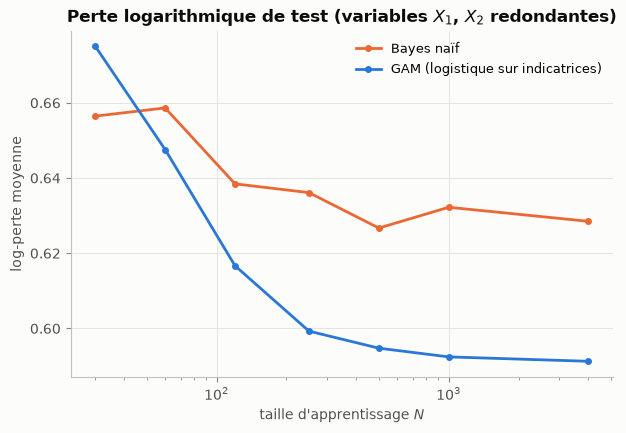

In [7]:
plt.figure(figsize=(7, 4.5))
for (name, v), c in zip(res.items(), (ORANGE, BLUE)):
    plt.semilogx(sizes, v, "o-", ms=4, color=c, label=name)
plt.title("Perte logarithmique de test (variables $X_1$, $X_2$ redondantes)")
plt.xlabel("taille d'apprentissage $N$"); plt.ylabel("log-perte moyenne"); plt.legend(); plt.show()

Pour de petits échantillons le Bayes naïf, plus contraint, est compétitif (variance
faible) ; quand $N$ grandit, il reste biaisé (il compte deux fois l'information portée par
$X_1$ et $X_2$, d'où des probabilités trop extrêmes) tandis que le GAM converge vers le
meilleur logit additif. Comparons les coefficients estimés sur un grand échantillon :

In [8]:
Xa, ga = simulate(200000, rng)
nb = nk.NaiveBayesKDE(discrete=[True] * 3).fit(Xa, ga)
lm = nb.log_marginals(np.array([[0, 0, 0], [1, 1, 1]], float))
coef_nb = (lm[1, 1] - lm[1, 0]) - (lm[0, 1] - lm[0, 0])
coef_gam = nk.logistic_irls(np.column_stack([np.ones(len(ga)), Xa]), ga)[1:]
print(pd.DataFrame({"Bayes naïf": coef_nb, "GAM": coef_gam}, index=["X1", "X2", "X3"]).round(3))

    Bayes naïf    GAM
X1       1.694  1.683
X2       1.329  0.016
X3       0.816  0.820


Le Bayes naïf attribue à $X_1$ **et** à $X_2$ leur plein effet marginal (log-rapports de
cotes $2\log(7/3)\approx1{,}69$ et $2\log(0{,}66/0{,}34)\approx1{,}33$), alors que le GAM
reconnaît que $X_2$ n'apporte rien une fois $X_1$ connu (coefficient $\approx 0$, ce qui est
exact : sachant $X_1$, $X_2$ est indépendante de la classe). Pour $X_3$, indépendante des
autres, les deux méthodes concordent.

> **À retenir.** Bayes naïf et GAM logistique partagent la **forme** additive du logit,
> mais le Bayes naïf l'obtient d'une hypothèse générative forte et d'une estimation
> marginale, le GAM d'une maximisation conjointe de la vraisemblance conditionnelle. Avec
> des variables discrètes, le GAM n'est autre que la régression logistique sur les
> indicatrices de modalités.

## Exercice 6.10 : Le critère $C_p$ est sans biais

**Énoncé.** On dispose de $N$ observations $y_i = f(x_i) + \varepsilon_i$, les
$\varepsilon_i$ i.i.d. de moyenne nulle et de variance $\sigma^2$, les $x_i$ étant fixés
(non aléatoires). On estime $f$ par un lisseur linéaire de paramètre $\lambda$ :
$\hat{\mathbf f} = \mathbf S_\lambda\mathbf y$. On considère l'erreur de prédiction dans
l'échantillon (éq. (6.34))
$$
\mathrm{PE}(\lambda) = \mathbb E\,\frac1N\sum_{i=1}^N\big(y_i^* - \hat f_\lambda(x_i)\big)^2
$$
pour de nouvelles réponses $y_i^*$ aux mêmes $x_i$. Montrer que l'erreur moyenne sur
l'apprentissage $\mathrm{ASR}(\lambda) = \frac1N\sum_i(y_i - \hat f_\lambda(x_i))^2$ est un
estimateur biaisé (optimiste) de $\mathrm{PE}(\lambda)$, tandis que (éq. (6.35))
$C_\lambda = \mathrm{ASR}(\lambda) + \frac{2\sigma^2}{N}\operatorname{trace}(\mathbf S_\lambda)$
est sans biais.

**Rappel (espérance d'une forme quadratique).** Si $\varepsilon$ est centré de covariance
$\sigma^2\mathbf I$ et $\mathbf M$ une matrice fixe, alors
$\mathbb E\|\mathbf a + \mathbf M\varepsilon\|^2 = \|\mathbf a\|^2 + \sigma^2\operatorname{trace}(\mathbf M^T\mathbf M)$
(on développe ; le terme croisé $2\mathbf a^T\mathbf M\,\mathbb E\varepsilon$ est nul, et
$\mathbb E\,\varepsilon^T\mathbf M^T\mathbf M\varepsilon = \operatorname{trace}(\mathbf M^T\mathbf M\,\mathbb E\varepsilon\varepsilon^T)$).

**Calcul de $\mathbb E\,\mathrm{ASR}$.** On écrit $\mathbf S = \mathbf S_\lambda$,
$\mathbf y = \mathbf f + \varepsilon$, donc
$\mathbf y - \mathbf S\mathbf y = (\mathbf I - \mathbf S)\mathbf f + (\mathbf I - \mathbf S)\varepsilon$ et
$$
N\,\mathbb E\,\mathrm{ASR} = \|(\mathbf I - \mathbf S)\mathbf f\|^2 + \sigma^2\operatorname{trace}\big((\mathbf I - \mathbf S)^T(\mathbf I - \mathbf S)\big)
= \|(\mathbf I - \mathbf S)\mathbf f\|^2 + \sigma^2\big(N - 2\operatorname{trace}\mathbf S + \operatorname{trace}(\mathbf S^T\mathbf S)\big),
$$
en utilisant $\operatorname{trace}(\mathbf S^T) = \operatorname{trace}(\mathbf S)$.

**Calcul de $\mathrm{PE}$.** Avec $\mathbf y^* = \mathbf f + \varepsilon^*$, $\varepsilon^*$
indépendant de $\varepsilon$ :
$\mathbf y^* - \mathbf S\mathbf y = (\mathbf I - \mathbf S)\mathbf f + \varepsilon^* - \mathbf S\varepsilon$.
Les trois termes croisés sont d'espérance nulle (indépendance et centrage), d'où
$$
N\,\mathrm{PE} = \|(\mathbf I - \mathbf S)\mathbf f\|^2 + N\sigma^2 + \sigma^2\operatorname{trace}(\mathbf S^T\mathbf S).
$$

**Conclusion.** En soustrayant :
$$
\mathrm{PE}(\lambda) - \mathbb E\,\mathrm{ASR}(\lambda) = \frac{2\sigma^2}{N}\operatorname{trace}(\mathbf S_\lambda).
$$
Pour les lisseurs usuels $\operatorname{trace}(\mathbf S_\lambda) = \mathrm{df}_\lambda > 0$ :
l'ASR **sous-estime** l'erreur de prédiction (elle est optimiste, d'autant plus que le
modèle est flexible). Et par linéarité de l'espérance,
$\mathbb E\,C_\lambda = \mathbb E\,\mathrm{ASR} + \frac{2\sigma^2}{N}\operatorname{trace}\mathbf S_\lambda = \mathrm{PE}(\lambda)$ :
$C_\lambda$ est **sans biais**. $\square$

Vérification par Monte-Carlo (linéaire local, tri-cube, $x_i$ fixés) :

In [9]:
sigma = np.sqrt(1 / 3)
fvec = np.sin(4 * x)
lams = np.geomspace(0.05, 1.0, 12)
R = 400
asr_m, cp_m, pe_m, pe_th = [], [], [], []
for l in lams:
    S = nk.smoother_matrix(x, lam=l, degree=1, kernel="tricube")
    a, c, pe = [], [], []
    for r in range(R):
        yy = fvec + sigma * rng.normal(size=N)
        ys = fvec + sigma * rng.normal(size=N)
        fh = S @ yy
        a.append(np.mean((yy - fh) ** 2)); c.append(nk.cp_criterion(S, yy, sigma ** 2))
        pe.append(np.mean((ys - fh) ** 2))
    asr_m.append(np.mean(a)); cp_m.append(np.mean(c)); pe_m.append(np.mean(pe))
    pe_th.append((np.sum((fvec - S @ fvec) ** 2) + N * sigma ** 2 + sigma ** 2 * np.trace(S.T @ S)) / N)

In [ ]:
plt.figure(figsize=(7, 4.5))
plt.semilogx(lams, pe_th, color=GRAY, lw=3, alpha=0.5, label="PE (formule exacte)")
plt.semilogx(lams, pe_m, "o", ms=4, color=GRAY, label="PE (Monte-Carlo)")
plt.semilogx(lams, asr_m, "o-", ms=3, color=BLUE, label="moyenne de ASR")
plt.semilogx(lams, cp_m, "s-", ms=3, color=ORANGE, label="moyenne de $C_\\lambda$")
plt.title("ASR est optimiste, $C_\\lambda$ est sans biais (%d répétitions)" % R)
plt.xlabel("$\\lambda$ (échelle log)"); plt.ylabel("erreur quadratique moyenne"); plt.legend(); plt.show()

> **À retenir.** L'optimisme de l'erreur d'apprentissage d'un lisseur linéaire vaut
> exactement $2\sigma^2\mathrm{df}_\lambda/N$ en espérance ; le corriger donne le critère
> $C_p$ (cf. section 7.4 du livre), qui nécessite une estimation de $\sigma^2$.

## Exercice 6.11 : La vraisemblance d'un mélange gaussien n'est pas bornée

**Énoncé.** Montrer que, pour le modèle de mélange gaussien (6.32), la vraisemblance
atteint $+\infty$ (n'est pas majorée) et décrire comment.

**Solution.** Plaçons-nous en dimension 1 avec $M\ge 2$ composantes (le cas $p > 1$ est
identique avec $\Sigma_1 = \sigma_1^2\mathbf I$). La vraisemblance est
$$
L = \prod_{i=1}^N\Big[\alpha_1\varphi(x_i;\mu_1,\sigma_1^2) + \sum_{m\ge2}\alpha_m\varphi(x_i;\mu_m,\sigma_m^2)\Big].
$$
Fixons $\mu_1 = x_1$ (une observation), $\alpha_1, \alpha_2 > 0$ et les paramètres
$(\mu_2, \sigma_2)$ quelconques, puis faisons $\sigma_1\to0$.

- **Facteur $i = 1$** : il est minoré par $\alpha_1\varphi(x_1; x_1, \sigma_1^2) = \frac{\alpha_1}{\sqrt{2\pi}\,\sigma_1}$,
  qui tend vers $+\infty$.
- **Facteurs $i\ge2$** : chacun est minoré par $\alpha_2\varphi(x_i;\mu_2,\sigma_2^2) = c_i > 0$,
  qui ne dépend pas de $\sigma_1$.

Donc $L\ \ge\ \frac{\alpha_1}{\sqrt{2\pi}\sigma_1}\prod_{i\ge2}c_i\ \xrightarrow[\sigma_1\to0]{}\ +\infty$.
Une composante « s'effondre » sur un seul point : sa densité y devient un pic infini, tandis
que les autres composantes expliquent le reste des données. Avec $M = 1$ ce phénomène est
impossible (les autres facteurs tendraient vers 0 plus vite).